# **Engineering Probability and Statistics**

## **Computer Assignment 6**

**School of Electrical and Computer Engineering**  
**College of Engineering, University of Tehran**

**Instructors:** Dr. Bahrak, Dr. Vahhabi  

**Topic:** Central Limit Theorem and Parameter Estimation

## **Table of Contents**

* **[Central Limit Theorem in Practice](#central-limit-theorem-in-practice)**

  * [Section 1: Skewed Daily Watch-Time Dataset](#section-1-skewed-daily-watch-time-dataset)

    * [Exploring the Dataset](#exploring-the-dataset)
    * [Section 1.1: Sample Means for Different Sample Sizes](#section-11-sample-means-for-different-sample-sizes)
    * [Section 1.2: Probability That the Sample Mean Lies in the Interval](#section-12-probability-that-the-sample-mean-lies-in-the-interval)
  * [Section 2: CLT for Simple Known Distributions](#section-2-clt-for-simple-known-distributions)

* **[Benford’s Law in Real-World Data](#benfords-law-in-real-world-data)**

  * [Section 1: Benford’s Law and the CLT Connection](#section-1-benfords-law-and-the-clt-connection)
  * [Section 2: Implementing Benford’s Law in R](#section-2-implementing-benfords-law-in-r)
  * [Section 3: Loading the Dataset and Constructing GDP](#section-3-loading-the-dataset-and-constructing-gdp)
  * [Section 4: Verifying Benford’s Law Using GDP](#section-4-verifying-benfords-law-using-gdp)



## **Central Limit Theorem in Practice**

### Section 1: SKEWED DAILY WATCH-TIME DATASET

#### Exploring the Dataset

In [1]:
set.seed(123)

n_users <- 5000

# Proportions of each user type
props <- c(light = 0.5, medium = 0.35, heavy = 0.15)

n_light  <- round(n_users * props["light"])
n_medium <- round(n_users * props["medium"])
n_heavy  <- n_users - n_light - n_medium

# Light users: mean 10, sd 4
light_users  <- rnorm(n_light,  mean = 10, sd = 4)

# Medium users: mean 40, sd 8
medium_users <- rnorm(n_medium, mean = 40, sd = 8)

# Heavy users: mean 90, sd 15
heavy_users  <- rnorm(n_heavy,  mean = 90, sd = 15)

watch_time <- c(light_users, medium_users, heavy_users)

# Truncate at 0 and 300 minutes to keep it realistic
watch_time[watch_time < 0]   <- 0
watch_time[watch_time > 300] <- 300

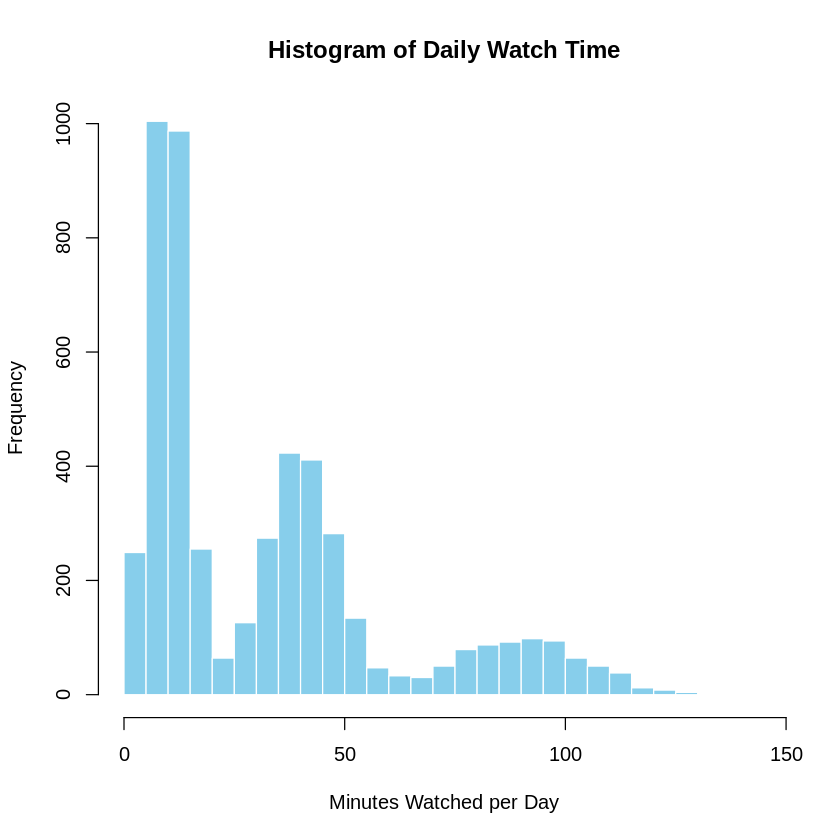

In [2]:
hist(
  watch_time,
  breaks = 50,
  col = "skyblue",
  border = "white",
  main = "Histogram of Daily Watch Time",
  xlab = "Minutes Watched per Day"
)

#### Section 1.1: Sample Means for Different Sample Sizes


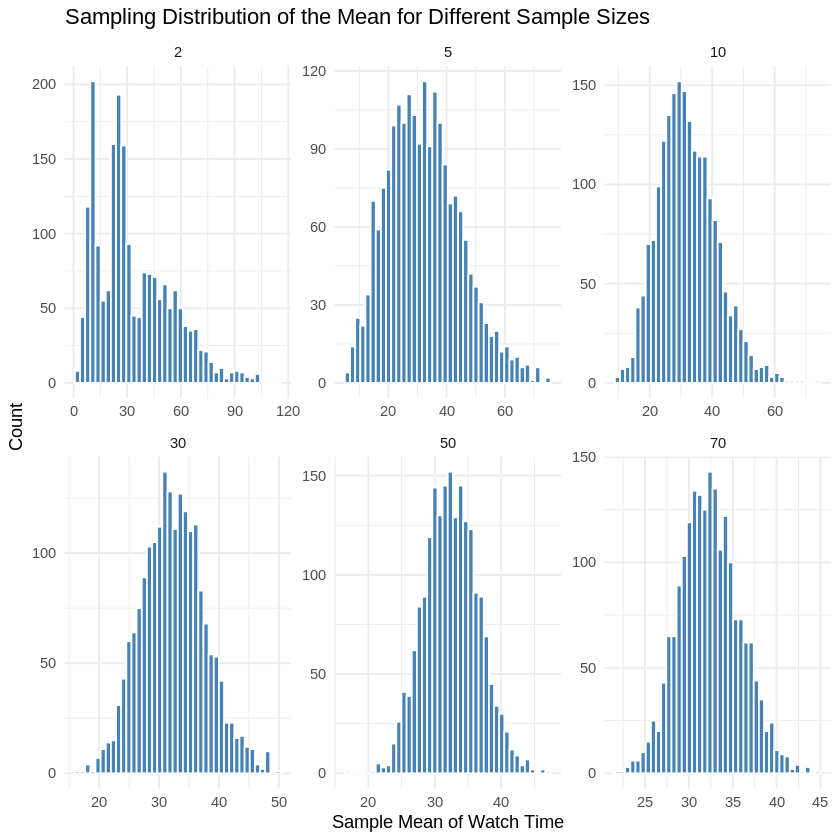

In [3]:
library(ggplot2)

# Sample sizes to study
sample_sizes <- c(2, 5, 10, 30, 50, 70)
B <- 2000  # number of repetitions for each n

sample_means <- data.frame()

for (n in sample_sizes) {
  means <- replicate(B, mean(sample(watch_time, n, replace = TRUE)))

  temp <- data.frame(
    mean_watch_time = means,
    sample_size = factor(n)
  )

  sample_means <- rbind(sample_means, temp)
}

ggplot(sample_means, aes(x = mean_watch_time)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  facet_wrap(~ sample_size, scales = "free") +
  labs(
    title = "Sampling Distribution of the Mean for Different Sample Sizes",
    x = "Sample Mean of Watch Time",
    y = "Count"
  ) +
  theme_minimal()

#### Section 1.2: Probability That the Sample Mean Lies in the Interval


Estimated mu (watch_time): 32.45821 
Estimated sigma (watch_time): 28.7749 
Standard Error: 4.795816 
Interval [a, b]: [ 22.86658 , 42.04984 ]
Theoretical CLT Probability: 0.9544997 
Simulated Probability: 0.9587 


Warning message:
“The dot-dot notation (`..density..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(density)` instead.”


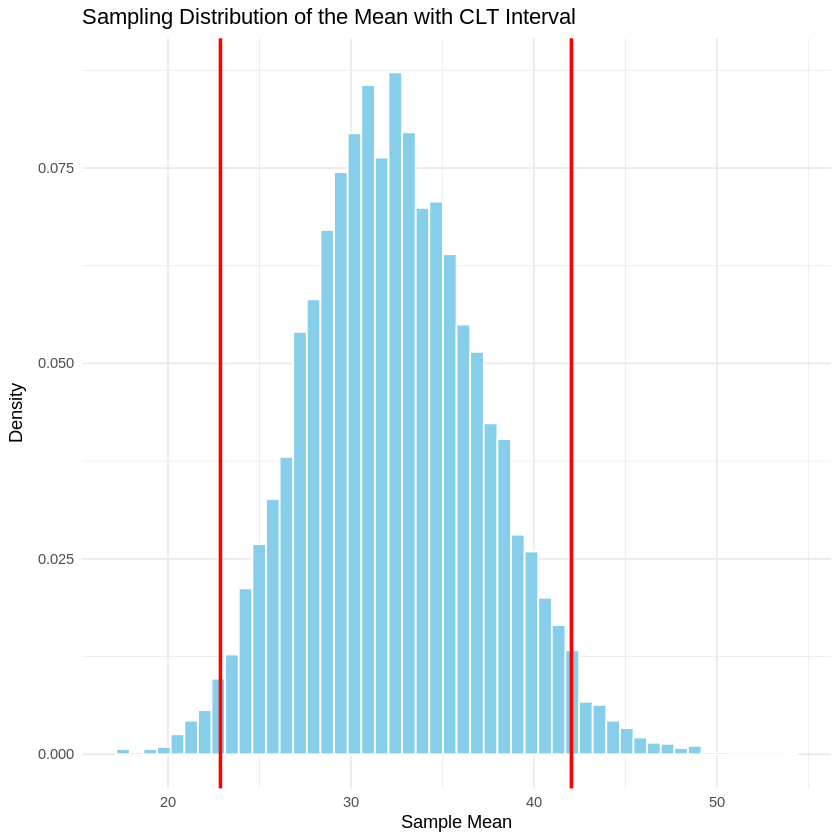

In [4]:
set.seed(789)

# Estimate MU and SIGMA from WATCH_TIME

mu_hat    <- mean(watch_time)
sigma_hat <- sd(watch_time)

cat("Estimated mu (watch_time):", mu_hat,    "\n")
cat("Estimated sigma (watch_time):", sigma_hat, "\n")


# Choose a sample size n
n <- 36

#         then build the 95%-style CLT band around the mean:
#         [a, b] = [mu_hat - 2*sigma_bar, mu_hat + 2*sigma_bar].
sigma_bar <- sigma_hat / sqrt(n)

a <- mu_hat - 2 * sigma_bar
b <- mu_hat + 2 * sigma_bar

cat("Standard Error:", sigma_bar, "\n")
cat("Interval [a, b]: [", a, ",", b, "]\n")


#         compute the theoretical probability P(a < X_bar < b) using pnorm().

theoretical_prob <- pnorm(b, mean = mu_hat, sd = sigma_bar) -
                    pnorm(a, mean = mu_hat, sd = sigma_bar)

cat("Theoretical CLT Probability:", theoretical_prob, "\n")

B <- 10000

#         generate B sample means by resampling from watch_time,
#         then compute the fraction that falls inside [a, b].

sim_means <- replicate(B, mean(sample(watch_time, n, replace = TRUE)))

sim_prob <- mean(sim_means > a & sim_means < b)

cat("Simulated Probability:", sim_prob, "\n")

#         and mark the interval boundaries a and b with two vertical red lines.

ggplot(data.frame(sim_means), aes(x = sim_means)) +
  geom_histogram(aes(y = ..density..), bins = 50,
                 fill = "skyblue", color = "white") +
  geom_vline(xintercept = a, color = "red", linewidth = 1) +
  geom_vline(xintercept = b, color = "red", linewidth = 1) +
  labs(
    title = "Sampling Distribution of the Mean with CLT Interval",
    x = "Sample Mean",
    y = "Density"
  ) +
  theme_minimal()

### Section 2: CLT for Simple Known Distributions

In Part 1, you saw that sample means from a messy, skewed “watch time” dataset became more and more bell‑shaped as the sample size increased. But maybe this was just a special case

In this part, you will:

Work with three simple, well‑known distributions:

- Uniform(0, 1)

- Exponential(rate = 1)

- Bernoulli(p = 0.3)

For each distribution:

- Generate raw data and plot its histogram to see the original shape.

- Generate many sample means for n = 5, 10, 30.

- Compare the histogram of the sample means with the theoretical normal curve predicted by the CLT:
mean = μ, variance = σ² / n.

In [6]:
set.seed(456)

B <- 2000
n_values <- c(5, 10, 30, 50, 70)

# Distribution generators
r_unif <- function(n) runif(n, min = 0, max = 1)
r_exp  <- function(n) rexp(n, rate = 1)
p_bern <- 0.3
r_bern <- function(n) rbinom(n, size = 1, prob = p_bern)

dist_list <- list(
  uniform     = r_unif,
  exponential = r_exp,
  bernoulli   = r_bern
)

# Theoretical mean (mu) and variance (sigma^2) for each distribution
dist_params <- list(
  uniform     = list(mu = 0.5, sigma2 = 1/12),
  exponential = list(mu = 1,   sigma2 = 1),
  bernoulli   = list(mu = p_bern,
                     sigma2 = p_bern * (1 - p_bern))
)

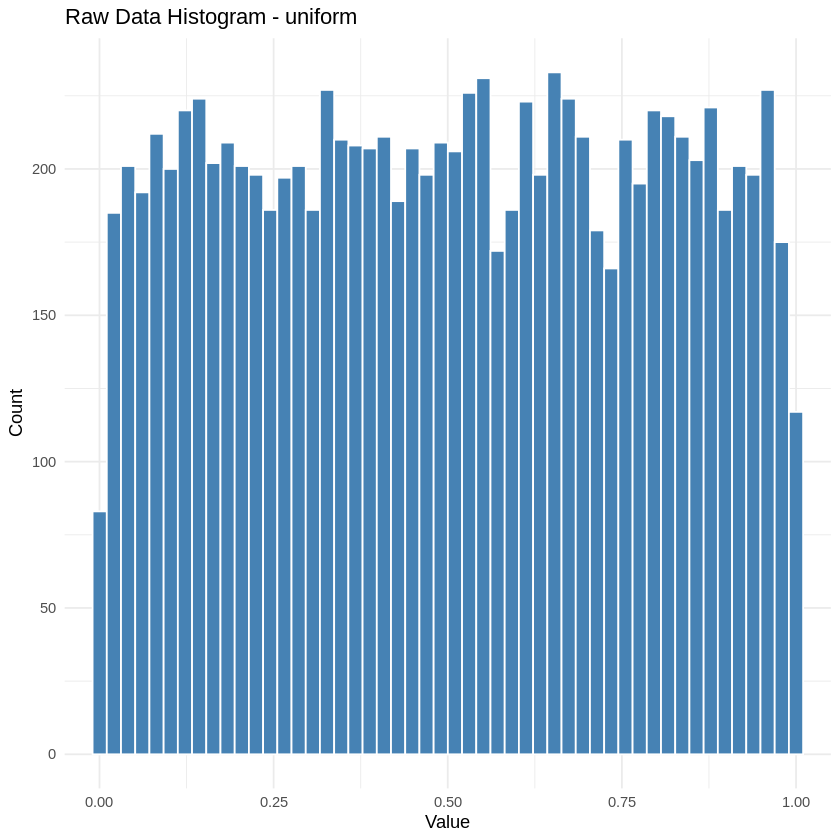

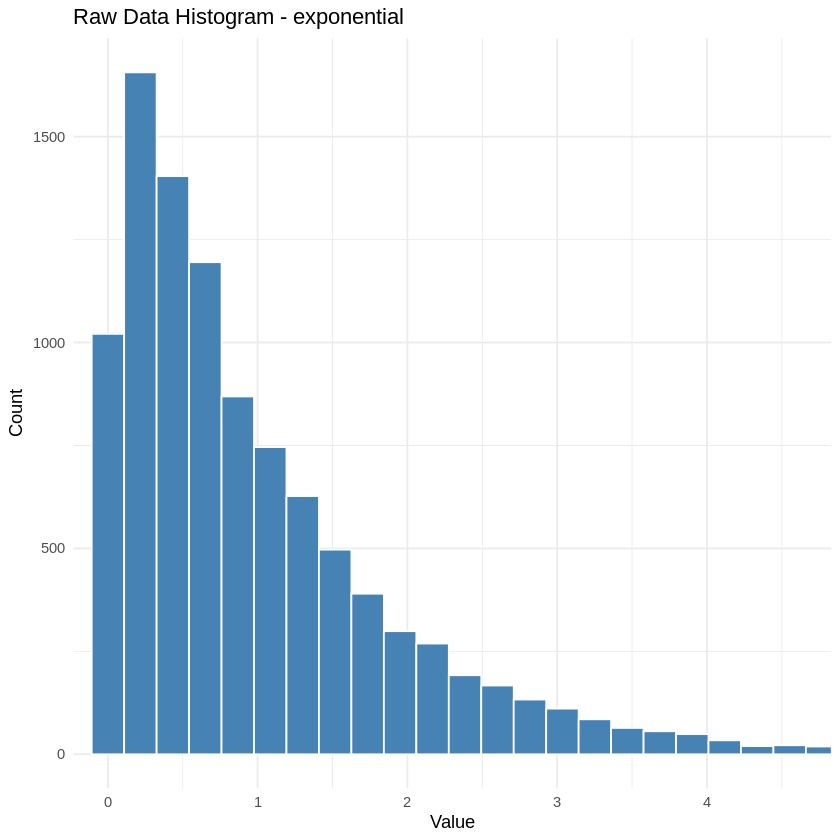

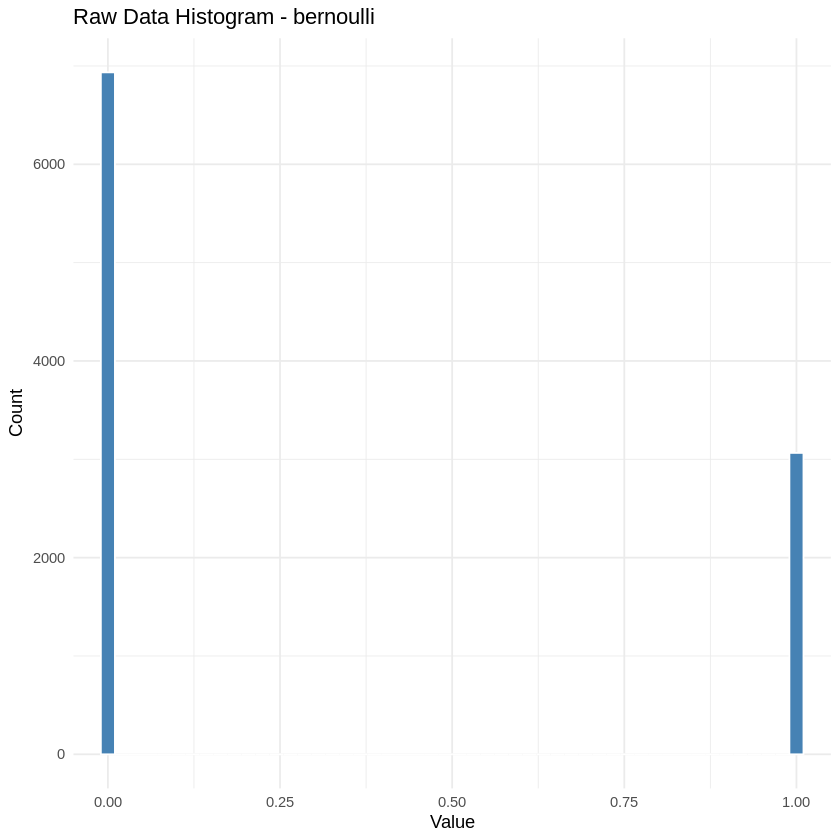

In [7]:
# IMPORTANT: Use the same x-axis limits for all histograms of a given distribution to allow proper comparison of variances.
library(ggplot2)

raw_data_list <- list()

for (dist_name in names(dist_list)) {

  gen_fun <- dist_list[[dist_name]]

  # generate raw data
  raw_vals <- gen_fun(10000)

  raw_data_list[[dist_name]] <- raw_vals

  # choose consistent x limits per distribution
  if (dist_name == "uniform") {
    xlims <- c(0, 1)
  } else if (dist_name == "exponential") {
    xlims <- c(0, quantile(raw_vals, 0.99))
  } else if (dist_name == "bernoulli") {
    xlims <- c(0, 1)
  }

  df <- data.frame(x = raw_vals)

  p <- ggplot(df, aes(x = x)) +
    geom_histogram(bins = 50, fill = "steelblue", color = "white") +
    coord_cartesian(xlim = xlims) +
    labs(
      title = paste("Raw Data Histogram -", dist_name),
      x = "Value",
      y = "Count"
    ) +
    theme_minimal()

  print(p)
}

## **Benford’s Law in Real-World Data**

### Section 1: Benford’s Law and the CLT connection


In this section you will:
1. Derive the Benford probability for the first digit:
$$
P(D=d)=\log_{10}\left(1+\frac{1}{d}\right),\quad d=1,\dots,9.
$$
2. Explain (conceptually) how the Central Limit Theorem (CLT) makes Benford’s law appear in real-world data.

*Note: the theoretical derivation and the conceptual CLT–Benford
discussion are not included in this notebook.*

### Section 2: Implementing Benford’s Law in R

In this section, you will implement Benford’s Law in R.
First, you will write a function that returns the theoretical Benford probability for a given leading digit.  
Then, you will use this function to compute the probabilities for all digits and visualize the Benford distribution.

[1] 0.30103000 0.17609126 0.12493874 0.09691001 0.07918125 0.06694679 0.05799195
[8] 0.05115252 0.04575749


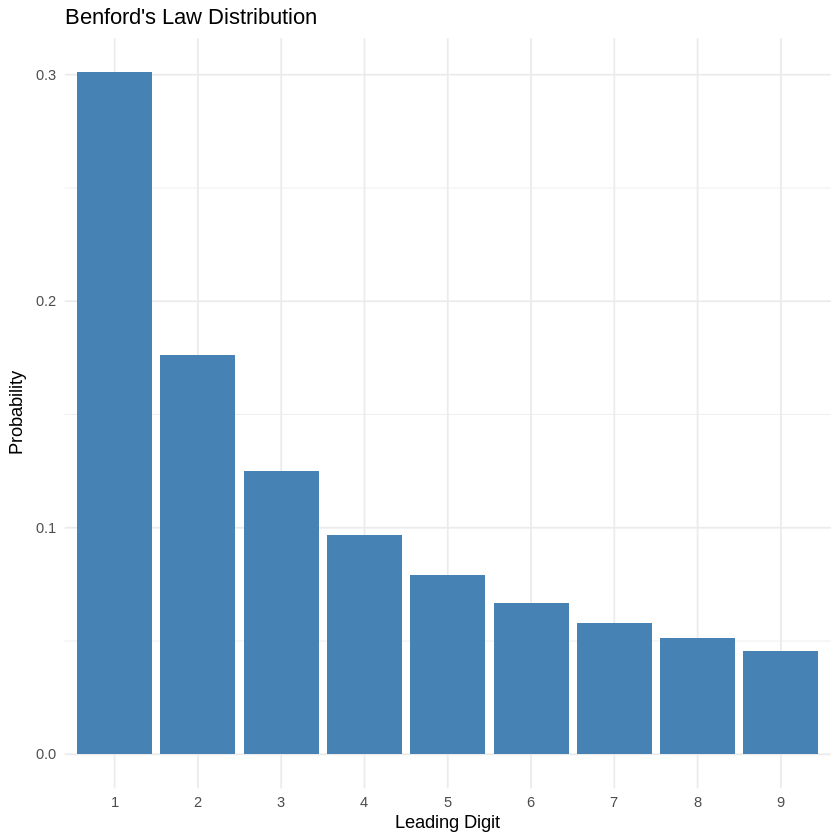

In [11]:
benford_prob <- function(n) {
  if (any(n < 1 | n > 9)) {
    stop("Digit must be between 1 and 9")
  }
  log10(1 + 1 / n)
}

digits <- 1:9
probs <- benford_prob(digits)

print(probs)
library(ggplot2)

df <- data.frame(
  digit = factor(digits),
  prob  = probs
)

ggplot(df, aes(x = digit, y = prob)) +
  geom_bar(stat = "identity", fill = "steelblue") +
  labs(
    title = "Benford's Law Distribution",
    x = "Leading Digit",
    y = "Probability"
  ) +
  theme_minimal()

### Section 3: Loading the Dataset and Constructing GDP

In this section, you will load a real-world dataset and construct a new variable using a meaningful economic relationship.
The dataset contains population and GDP per capita values for different countries and years. Using these variables, you will compute the total Gross Domestic Product (GDP) as:
$$
\text{GDP} = \text{population} \times \text{GDP per capita}.
$$
This constructed variable will later be used to study the distribution of leading digits and compare it with Benford’s Law. **Why can this be an appropriate variable to verify the Benford's law?**

In [14]:
install.packages("gapminder")
library(gapminder)

data <- gapminder
data$GDP <- data$pop * data$gdpPercap
head(data)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



country,continent,year,lifeExp,pop,gdpPercap,GDP
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453,6567086330
Afghanistan,Asia,1957,30.332,9240934,820.8530,7585448670
Afghanistan,Asia,1962,31.997,10267083,853.1007,8758855797
Afghanistan,Asia,1967,34.020,11537966,836.1971,9648014150
Afghanistan,Asia,1972,36.088,13079460,739.9811,9678553274
Afghanistan,Asia,1977,38.438,14880372,786.1134,11697659231


### Section 4: Verifying Benford’s Law Using GDP

In this section, you will empirically verify Benford’s Law using the GDP variable constructed in the previous section.
You will extract the leading digit of GDP values, compute the empirical distribution of leading digits, and **compare** it with the theoretical Benford distribution.

gdp_digits
         1          2          3          4          5          6          7 
0.30281690 0.17370892 0.12147887 0.09859155 0.07981221 0.06924883 0.05809859 
         8          9 
0.04636150 0.04988263 

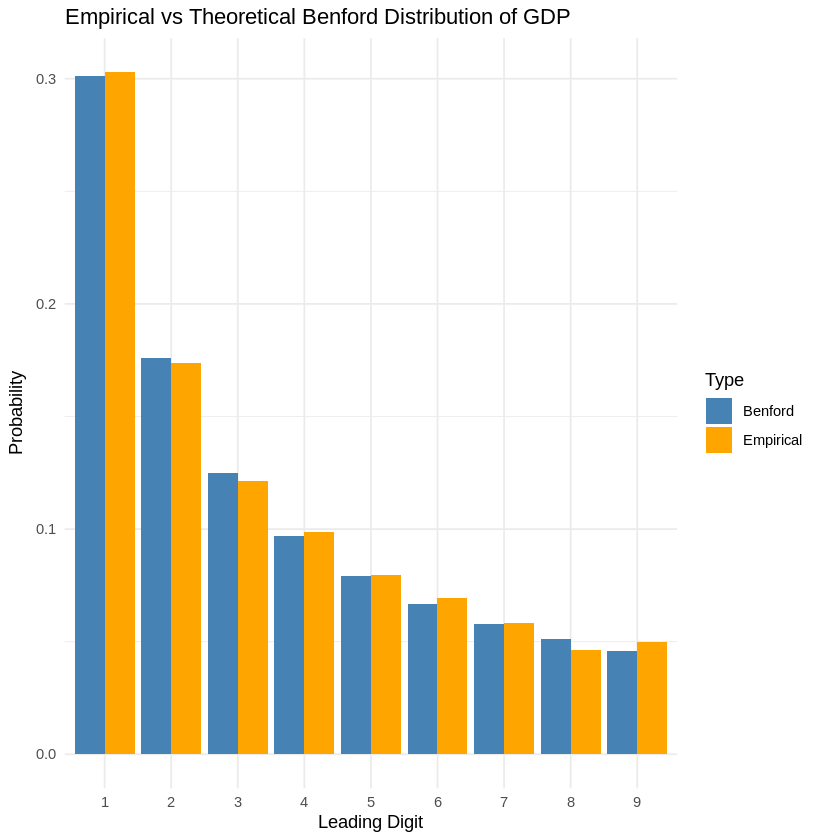

In [17]:
leading_digit <- function(x) {
  x <- x[!is.na(x) & x > 0]           # حذف مقادیر NA و صفر یا منفی
  first_digit <- as.numeric(substr(as.character(x), 1, 1))
  return(first_digit)
}
gdp_digits <- leading_digit(data$GDP)

empirical_freq <- table(gdp_digits) / length(gdp_digits)
empirical_freq

library(ggplot2)
library(tidyr)

digits <- 1:9
benford_probs <- log10(1 + 1 / digits)

 empirical_freq <- table(gdp_digits) / length(gdp_digits)

df <- data.frame(
  digit = factor(digits),
  Empirical = as.numeric(empirical_freq),
  Benford = benford_probs
)

df_long <- pivot_longer(df, cols = c("Empirical", "Benford"),
                        names_to = "Type", values_to = "Probability")

ggplot(df_long, aes(x = digit, y = Probability, fill = Type)) +
  geom_bar(stat = "identity", position = "dodge") +
  labs(
    title = "Empirical vs Theoretical Benford Distribution of GDP",
    x = "Leading Digit",
    y = "Probability"
  ) +
  scale_fill_manual(values = c("steelblue", "orange")) +
  theme_minimal()